# Lending game — EDA and train/test split

Explores the past loans (target, shared features, private signals), checks that the new applications come from the same population, and creates the shared train/test split.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.model_selection import train_test_split

SEED = 42
RAW_DIR = Path("../data/raw")
PROCESSED_DIR = Path("../data/processed")

SIGNALS = ["signal1", "signal2", "signal3"]
COLORS = ["#0072B2", "#E69F00", "#009E73"]  # Okabe-Ito, colorblind-safe

print(f"scikit-learn {sklearn.__version__}")  # the split is reproducible for a given version

scikit-learn 1.9.1


## 1. Load data

In [2]:
past = pd.read_csv(RAW_DIR / "PastLoans.csv")
new = pd.read_csv(RAW_DIR / "NewApplications_Lender3_Round1.csv")

# Past loans have no id: number rows 1..n, like the applications file
past.insert(0, "id", np.arange(1, len(past) + 1))

print(f"Past loans: {past.shape} | new applications: {new.shape}")
past.head()

Past loans: (100000, 9) | new applications: (100000, 6)


,id,sex,employment,married,income,signal1,signal2,signal3,default
0,1,M,unemployed,0,0,0.749267,0.422656,0.738735,0
1,2,M,employed,1,26108,0.697428,0.596361,0.733947,0
2,3,M,employed,1,11810,0.000000,0.652496,0.000000,0
3,4,M,unemployed,1,0,0.000000,0.000000,0.000000,0
4,5,F,retired,1,6310,0.000000,0.041123,0.203202,0


In [3]:
past.info()
print(f"\nMissing values: {past.isna().sum().sum()} (past), {new.isna().sum().sum()} (new)")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   id          100000 non-null  int64  
 1   sex         100000 non-null  object 
 2   employment  100000 non-null  object 
 3   married     100000 non-null  int64  
 4   income      100000 non-null  int64  
 5   signal1     100000 non-null  float64
 6   signal2     100000 non-null  float64
 7   signal3     100000 non-null  float64
 8   default     100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB

Missing values: 0 (past), 0 (new)


In [4]:
past.describe().round(3)

,id,married,income,signal1,signal2,signal3,default
count,100000.000,100000.000,100000.000,100000.000,100000.000,100000.000,100000.000
mean,50000.500,0.608,18646.254,0.418,0.416,0.415,0.099
std,28867.658,0.488,48178.199,0.325,0.325,0.325,0.299
min,1.000,0.000,0.000,0.000,0.000,0.000,0.000
25%,25000.750,0.000,5385.000,0.065,0.063,0.060,0.000
50%,50000.500,1.000,9370.000,0.448,0.445,0.441,0.000
75%,75000.250,1.000,17474.250,0.696,0.695,0.692,0.000
max,100000.000,1.000,1000000.000,1.000,1.000,1.000,1.000


## 2. Target: `default`

`default = 1` if the borrower did not repay. The classes are imbalanced, so accuracy is misleading (predicting "no default" for everyone is ~90% accurate). Models are compared on predicted probabilities (log loss, Brier score, calibration) and ranking (AUC).

Default rate: 9.95%


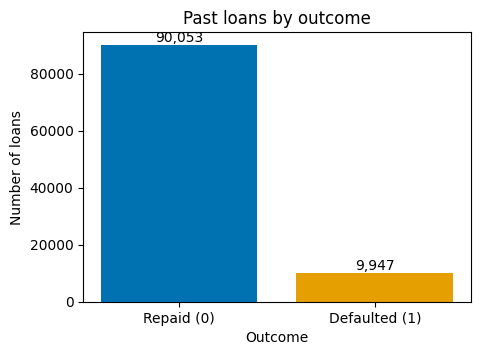

In [5]:
counts = past["default"].value_counts().sort_index()
print(f"Default rate: {past['default'].mean():.2%}")

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(["Repaid (0)", "Defaulted (1)"], counts.values, color=COLORS[:2])
for i, n in enumerate(counts.values):
    ax.text(i, n, f"{n:,}", ha="center", va="bottom")
ax.set(title="Past loans by outcome", xlabel="Outcome", ylabel="Number of loans")
plt.show()

## 3. Shared features

### Categorical features

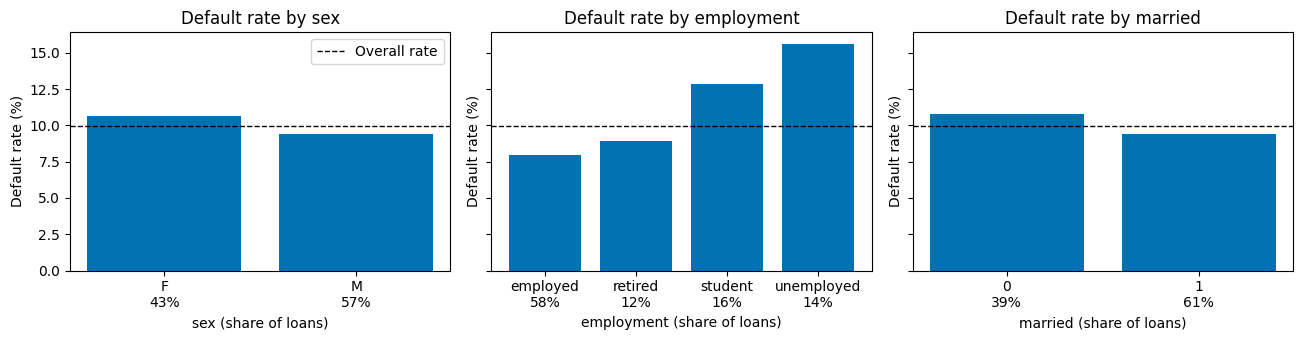

In [6]:
CATEGORICAL = ["sex", "employment", "married"]
overall_rate = past["default"].mean() * 100

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, col in zip(axes, CATEGORICAL):
    rates = past.groupby(col)["default"].mean() * 100
    shares = past[col].value_counts(normalize=True)
    labels = [f"{g}\n{shares[g]:.0%}" for g in rates.index]  # group and its share of loans
    ax.bar(labels, rates.values, color=COLORS[0])
    ax.axhline(overall_rate, color="black", ls="--", lw=1, label="Overall rate")
    ax.set(title=f"Default rate by {col}", xlabel=f"{col} (share of loans)", ylabel="Default rate (%)")
axes[0].legend()
plt.tight_layout()
plt.show()

### Income

Annual income in euros, top-coded at 1M € (higher incomes are recorded as 1M). It is right-skewed, so it is plotted on a log scale; zero incomes have no log and are counted separately.

Zero income: 17.04% of loans, default rate 20.19%
Top-coded at 1M €: 71 loans


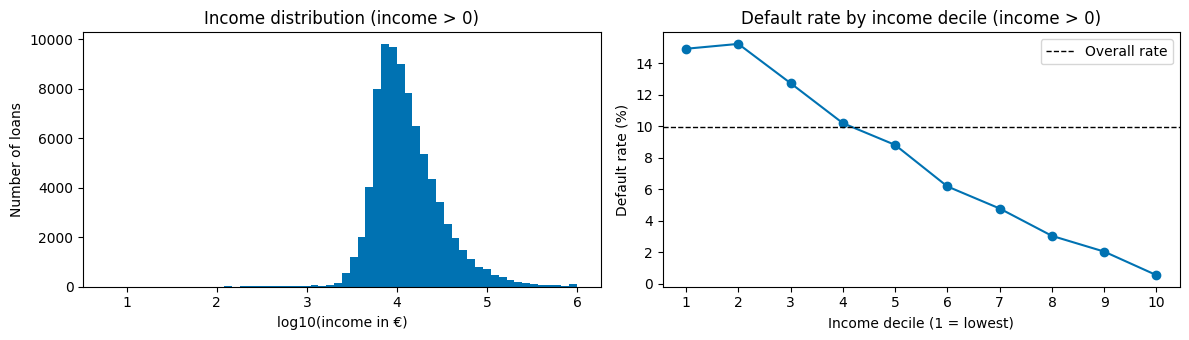

In [7]:
income = past["income"]
print(f"Zero income: {(income == 0).mean():.2%} of loans, default rate {past.loc[income == 0, 'default'].mean():.2%}")
print(f"Top-coded at 1M €: {(income == 1_000_000).sum():,} loans")

# Deciles of positive incomes; zero incomes form their own group
positive = past[income > 0]
decile = pd.qcut(positive["income"], 10, labels=False) + 1
rate_by_decile = positive.groupby(decile)["default"].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(np.log10(positive["income"]), bins=60, color=COLORS[0])
axes[0].set(title="Income distribution (income > 0)", xlabel="log10(income in €)", ylabel="Number of loans")
axes[1].plot(rate_by_decile.index, rate_by_decile.values, marker="o", color=COLORS[0])
axes[1].axhline(overall_rate, color="black", ls="--", lw=1, label="Overall rate")
axes[1].set(title="Default rate by income decile (income > 0)", xlabel="Income decile (1 = lowest)",
            ylabel="Default rate (%)", xticks=range(1, 11))
axes[1].legend()
plt.tight_layout()
plt.show()

## 4. Private signals

Each lender's private signal is a score in [0, 1] built from its own proprietary data. Past loans contain all three; for new applicants a lender only sees its own. About a fifth of each signal is exactly 0. This is a *mass point*: many rows share one value, which can behave differently from small positive values, so zeros are kept as a separate group below.

In [8]:
is_zero = past[SIGNALS] == 0
pd.DataFrame({
    "mean": past[SIGNALS].mean(),
    "share_zero": is_zero.mean(),
    "default_rate_if_zero": [past.loc[is_zero[s], "default"].mean() for s in SIGNALS],
    "default_rate_if_positive": [past.loc[~is_zero[s], "default"].mean() for s in SIGNALS],
}).round(3)

,mean,share_zero,default_rate_if_zero,default_rate_if_positive
signal1,0.418,0.208,0.095,0.101
signal2,0.416,0.209,0.097,0.100
signal3,0.415,0.211,0.097,0.100


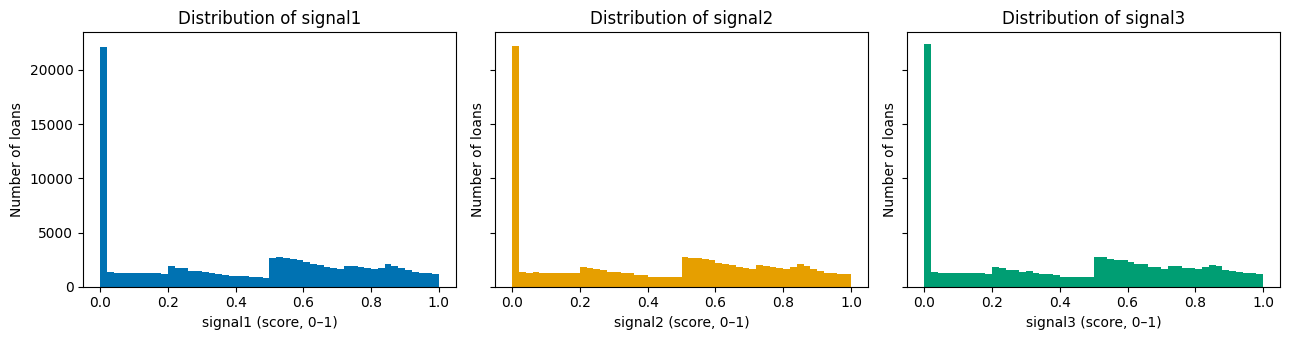

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, s, color in zip(axes, SIGNALS, COLORS):
    ax.hist(past[s], bins=50, color=color)
    ax.set(title=f"Distribution of {s}", xlabel=f"{s} (score, 0–1)", ylabel="Number of loans")
plt.tight_layout()
plt.show()

Default rate by signal bin: zeros as their own group, then deciles of the positive values. Binning shows the shape of the relationship without assuming it is linear.

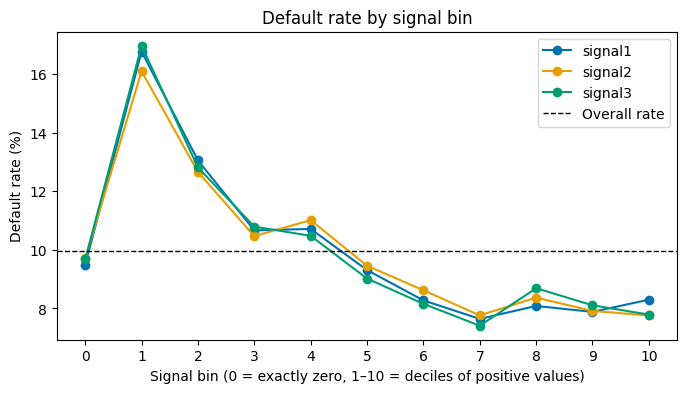

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
for s, color in zip(SIGNALS, COLORS):
    pos = past[past[s] > 0]
    by_decile = pos.groupby(pd.qcut(pos[s], 10, labels=False) + 1)["default"].mean() * 100
    rates = [past.loc[past[s] == 0, "default"].mean() * 100, *by_decile.values]
    ax.plot(range(11), rates, marker="o", color=color, label=s)
ax.axhline(overall_rate, color="black", ls="--", lw=1, label="Overall rate")
ax.set(title="Default rate by signal bin", xlabel="Signal bin (0 = exactly zero, 1–10 = deciles of positive values)",
       ylabel="Default rate (%)", xticks=range(11))
ax.legend()
plt.show()

In [11]:
print("Correlation between signals:")
display(past[SIGNALS].corr().round(2))

# How many of the three signals are zero for the same borrower
print("Number of zero signals per borrower (share of loans):")
is_zero.sum(axis=1).value_counts(normalize=True).sort_index().round(3)

Correlation between signals:


,signal1,signal2,signal3
signal1,1.00,0.17,0.18
signal2,0.17,1.00,0.18
signal3,0.18,0.18,1.00


Number of zero signals per borrower (share of loans):


0    0.505
1    0.375
2    0.108
3    0.013
Name: proportion, dtype: float64

## 5. Past loans vs new applications

The new applicants are drawn from the same population as the past loans, so the shared features and `signal3` should have the same distributions in both files. This guards against loading or encoding problems.

In [12]:
compare = pd.DataFrame({
    "past": [past["income"].median(), past["married"].mean(), past["signal3"].mean(), (past["signal3"] == 0).mean()],
    "new": [new["income"].median(), new["married"].mean(), new["signal3"].mean(), (new["signal3"] == 0).mean()],
}, index=["income (median)", "married (share)", "signal3 (mean)", "signal3 (share zero)"])
display(compare.round(3))

for col in ["sex", "employment"]:
    display(pd.DataFrame({
        "past": past[col].value_counts(normalize=True),
        "new": new[col].value_counts(normalize=True),
    }).round(3))

,past,new
income (median),9370.000,9349.000
married (share),0.608,0.611
signal3 (mean),0.415,0.416
signal3 (share zero),0.211,0.209


,past,new
sex,,
M,0.573,0.572
F,0.427,0.428


,past,new
employment,,
employed,0.579,0.578
student,0.162,0.160
unemployed,0.143,0.145
retired,0.116,0.116


### EDA Takeaways
- Default rate is 9.95%
- 58% is employed, remainder distributed between retired, student, unemployed
- 57% male, 61% married


**versus features**
1. By sex: basically mean
2. By employment: higher than mean for students and unemployed
3. By marriage status: basically mean
4. v Income: 17% of loans have 0 income (default 20.19%), default rate goes down with higher income decile.

**private signals**
1. Low correlation between signals
2. 20% are exactly 0 for each of the 3
3. The higher the signal, the lower the default rate.

Similar distribution for past and new datasets.




## 6. Train/test split

- **70/30 split, stratified on `default`**: both sets keep the same default rate, so test scores aren't distorted by an unlucky draw of defaulters.
- **Fixed `random_state`**: everyone gets the same rows. Which rows land in the test set depends only on the number of rows, the target and the seed, not on the columns, so all features are kept and each model selects its own.
- **The test set is used once**, for the final model comparison. Tuning uses cross-validation on the training set, otherwise the test score is optimistic (leakage).

In [13]:
train, test = train_test_split(past, test_size=0.3, random_state=SEED, stratify=past["default"])

for name, part in [("train", train), ("test", test)]:
    print(f"{name}: {len(part):,} rows, default rate {part['default'].mean():.2%}")

train: 70,000 rows, default rate 9.95%
test: 30,000 rows, default rate 9.95%


In [14]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
train.to_csv(PROCESSED_DIR / "train.csv", index=False)
test.to_csv(PROCESSED_DIR / "test.csv", index=False)
print(f"Saved train.csv and test.csv to {PROCESSED_DIR}")

Saved train.csv and test.csv to ../data/processed
